<a href="https://colab.research.google.com/github/Kevin-AngelQD/padp/blob/main/PracticaArbolDecisiones271758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Actividad: Árbol de Decisión para Regresión

**Objetivo**

Analizar el comportamiento de un modelo de **árbol de decisión** en un problema de regresión, evaluando su capacidad de generalización mediante el estudio del **sobreajuste, la profundidad del árbol y la poda.**

# Dataset
Se utilizará el dataset California Housing, disponible en scikit-learn.

Kevin Quiñonez
271758

**1. Carga y exploración de datos**
*   Cargar el dataset en un DataFrame
*   Identificar la variable objetivo (MedHouseVal)
*   Analizar la estructura del dataset (info, describe)
*   Visualizar la distribución de la variable objetivo



--- Info de California Housing ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


None

--- Describe de California Housing ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


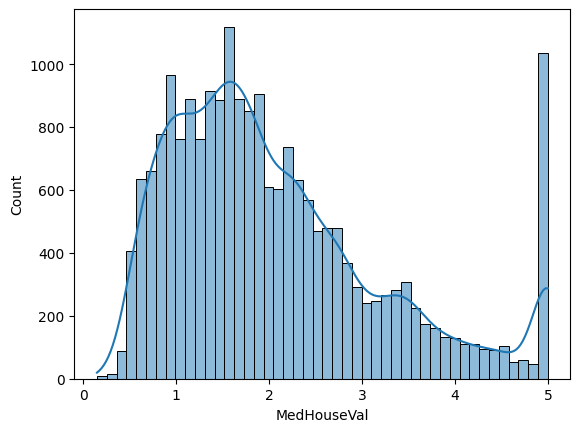

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


california = fetch_california_housing(as_frame=True)
df = california.frame #Ya incluye MedHouseVal


print("--- Info de California Housing ---")
display(df.info())
print("--- Describe de California Housing ---")
display(df.describe())

sns.histplot(data=df, x='MedHouseVal', kde=True)  # kde=True añade la línea de densidad
plt.show()

# Análisis e Interpretación de Resultados

1. **Estructura del Dataset (df.info()):**
El conjunto de datos consta de 20,640 observaciones y 9 variables numéricas.No existen valores nulos o faltantes (todas las columnas muestran 20640 non-null).   Tipos de Datos: Todas las columnas son de tipo continuo (float64), por lo que no se requiere codificación categórica previa.   

2. **Estadísticas Descriptivas (df.describe()):**
Variable Objetivo (MedHouseVal): Mide el valor medio de las viviendas expresado en cientos de miles de dólares ($\$100,000$ USD).   La media es de $2.068$ ($\approx \$206,855$ USD).   La mediana (percentil 50) es de $1.797$ ($\approx \$179,700$ USD).   El rango va desde un mínimo de $0.1499$ ($\approx \$15,000$ USD) hasta un máximo de $5.00001$ ($\approx \$500,000$ USD).   Escalas Heterogéneas: Se observa una disparidad notable en las escalas de los predictores; por ejemplo, Population alcanza un valor máximo de $35,682$ habitantes, mientras que AveBedrms tiene una media de $1.09$. (Nota: Los árboles de decisión son inmunes a los problemas de escala, por lo que no requerirán estandarización).   


3. Distribución de la Variable Objetivo (MedHouseVal)Sesgo Positivo: Presenta un sesgo moderado hacia la derecha, concentrando la mayor densidad de viviendas entre los valores $1.0$ y $2.5$ ($\$100,000$ y $\$250,000$ USD).   Truncamiento Censurado (Pico en $5.0$): Se aprecia un pico artificial muy marcado en el extremo derecho ($5.0$). Esto se debe a que el dataset original de California Housing fue censurado (capped): todas las casas con un valor igual o superior a $\$500,000$ USD fueron agrupadas directamente en la categoría límite de $5.0$.   


**2. Preparación de datos**
*   X: variables predictoras
*   y: variable objetivo
* Dividir los datos en entrenamiento (80%) y prueba (20%)




In [2]:


X = df.drop(columns='MedHouseVal')  # Características
y = df['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Probar la dimensión y proporciones de la división
print(f"Total de datos en df: {len(df)}")
print(f"X_train shape: {X_train.shape} -> ({X_train.shape[0] / len(df):.0%} del total)")
print(f"X_test shape:  {X_test.shape}  -> ({X_test.shape[0] / len(df):.0%} del total)")

Total de datos en df: 20640
X_train shape: (16512, 8) -> (80% del total)
X_test shape:  (4128, 8)  -> (20% del total)


**3. Modelo base**
*   Entrenar un árbol de decisión sin restricciones (max_depth=None)
*   Evaluar el modelo usando.
      *   RMSE
      *   R²
* Comparar desempeño en entrenamiento y prueba
* Determinar si existe sobreajuste

In [3]:
from sklearn.tree import DecisionTreeRegressor
arbol_base = DecisionTreeRegressor(
    random_state=42
    # Sin max_depth → crece hasta hojas puras (overfitting)
)
arbol_base.fit(X_train, y_train)

print("--- Arbol de decision sin restricciones ---")


print("Profundidad:", arbol_base.get_depth())
print("Número de hojas:", arbol_base.get_n_leaves())
print("Número de nodos:", arbol_base.tree_.node_count)


print("\n--- Evaluacion del modelo usando RMSE y R²  ---")
def evaluar_modelo(modelo, X_tr, y_tr, X_te, y_te, nombre='Modelo'):
    """Calcula RMSE, MAE y R² para train y test."""
    y_pred_tr = modelo.predict(X_tr)
    y_pred_te = modelo.predict(X_te)

    resultados = {
        'nombre':    nombre,
        'RMSE_train': np.sqrt(mean_squared_error(y_tr, y_pred_tr)),
        'RMSE_test':  np.sqrt(mean_squared_error(y_te, y_pred_te)),
        'MAE_train':  mean_absolute_error(y_tr, y_pred_tr),
        'MAE_test':   mean_absolute_error(y_te, y_pred_te),
        'R2_train':   r2_score(y_tr, y_pred_tr),
        'R2_test':    r2_score(y_te, y_pred_te),
    }
    return resultados

from IPython.display import display, Markdown

def imprimir_metricas(res):
    gap_rmse = res['RMSE_test'] - res['RMSE_train']


    md = f"""
### Métricas: {res['nombre']}

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | {res['RMSE_train']:.4f} | {res['RMSE_test']:.4f} | Error en $100k; menor es mejor |
| **MAE**  | {res['MAE_train']:.4f}  | {res['MAE_test']:.4f}  | Error absoluto medio |
| **R²**   | {res['R2_train']:.4f}   | {res['R2_test']:.4f}   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** {gap_rmse:.4f}
"""
    display(Markdown(md))

# ─── 4.2 Evaluación del árbol base ───────────────────────────────────────────
res_base = evaluar_modelo(arbol_base, X_train, y_train, X_test, y_test, 'Árbol Base (sin restricciones)')
imprimir_metricas(res_base)



--- Arbol de decision sin restricciones ---
Profundidad: 34
Número de hojas: 15854
Número de nodos: 31707

--- Evaluacion del modelo usando RMSE y R²  ---



### Métricas: Árbol Base (sin restricciones)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.0000 | 0.7037 | Error en $100k; menor es mejor |
| **MAE**  | 0.0000  | 0.4547  | Error absoluto medio |
| **R²**   | 1.0000   | 0.6221   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.7037


**Comparar desempeño en entrenamiento y prueba:**

Hay una discrepancia masiva entre el desempeño de entrenamiento ($R^2 = 1.0000$, $\text{RMSE} = 0.0000$) y el de prueba ($R^2 = 0.6221$, $\text{RMSE} = 0.7037$). Al entrenar con max_depth=None, el árbol creció sin control hasta memorizar el ruido específico de los datos de entrenamiento.


**Determinar si existe sobreajuste:**

Regla empírica: Si $R^2_{\text{train}} - R^2_{\text{test}} > 0.10$ (o si la diferencia en RMSE/MAE es muy amplia), hay evidencia de sobreajuste.

En este caso: $R^2_{\text{train}} = 1.0000$ vs $R^2_{\text{test}} = 0.6221$ $\rightarrow$ Diferencia de $0.3779$ ($37.8\%$).   

$\text{RMSE}_{\text{train}} = 0.0000$ vs $\text{RMSE}_{\text{test}} = 0.7037$ $\rightarrow$ Gap de $0.7037$.   

Esta brecha masiva es la prueba cuantitativa definitiva de sobreajuste.

**4. Análisis Bias–Variance**
* Entrenar múltiples modelos variando el parámetro max_depth de 1 a 21.
* Graficar el error (RMSE) en entrenamiento y prueba
* Identificar el punto donde el modelo generaliza mejor

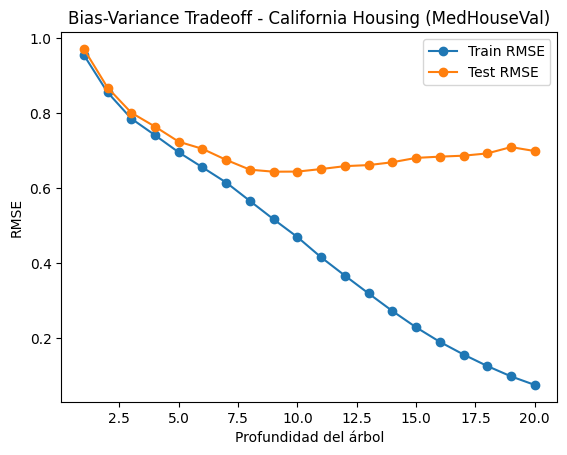

La profundidad óptima es max_depth = 9 con un RMSE de test de 0.6443


In [4]:
depths = list(range(1, 21))

rmse_train = []
rmse_test = []

for d in depths:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    rmse_train.append(np.sqrt(mean_squared_error(y_train, y_pred_train)))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, y_pred_test)))


plt.figure()
plt.plot(depths, rmse_train, marker='o', label="Train RMSE")
plt.plot(depths, rmse_test, marker='o', label="Test RMSE")

plt.xlabel("Profundidad del árbol")
plt.ylabel("RMSE")
plt.title("Bias-Variance Tradeoff - California Housing (MedHouseVal)")
plt.legend()
plt.show()

best_depth = depths[np.argmin(rmse_test)]
min_rmse = min(rmse_test)

print(f"La profundidad óptima es max_depth = {best_depth} con un RMSE de test de {min_rmse:.4f}")

**5. Poda de arbol**
* Aplicar cost-complexity pruning (ccp_alpha)
* Evaluar distintos valores de ccp_alpha con ccp_alphas = ccp_alphas[::5]
* Analizar su efecto en el error del modelo


In [5]:
# 1. Obtener ruta de poda
# Modelo base para obtener alphas
path = DecisionTreeRegressor(random_state=42).cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas

#2. Entrenar modelos con distintos niveles de poda
rmse_train = []
rmse_test = []
alphas = []

ccp_alphas = ccp_alphas[::5]  # tomar cada 5

for alpha in ccp_alphas:
    model = DecisionTreeRegressor(random_state=42,max_depth=10, ccp_alpha=alpha)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    rmse_train.append(np.sqrt(mean_squared_error(y_train, y_pred_train)))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, y_pred_test)))
    alphas.append(alpha)

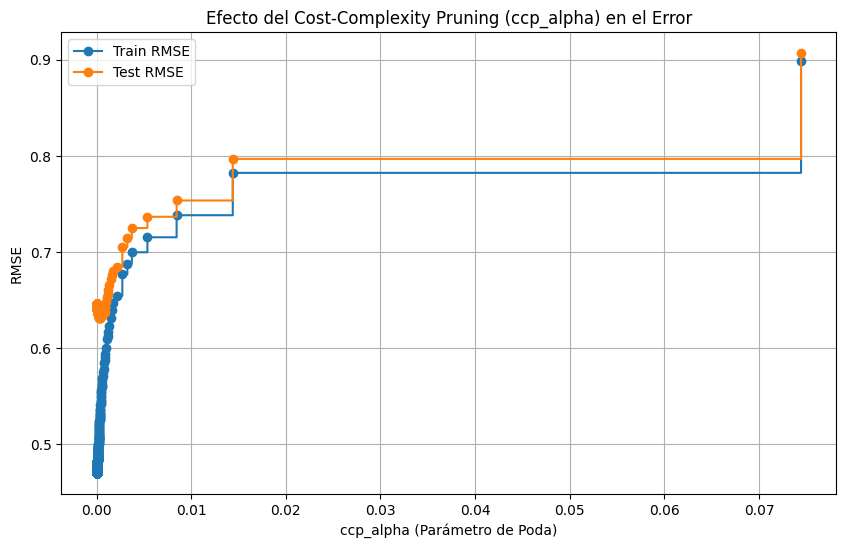

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(alphas, rmse_train, marker='o', label='Train RMSE', drawstyle="steps-post")
plt.plot(alphas, rmse_test, marker='o', label='Test RMSE', drawstyle="steps-post")

plt.xlabel("ccp_alpha (Parámetro de Poda)")
plt.ylabel("RMSE")
plt.title("Efecto del Cost-Complexity Pruning (ccp_alpha) en el Error")
plt.legend()
plt.grid(True)
plt.show()

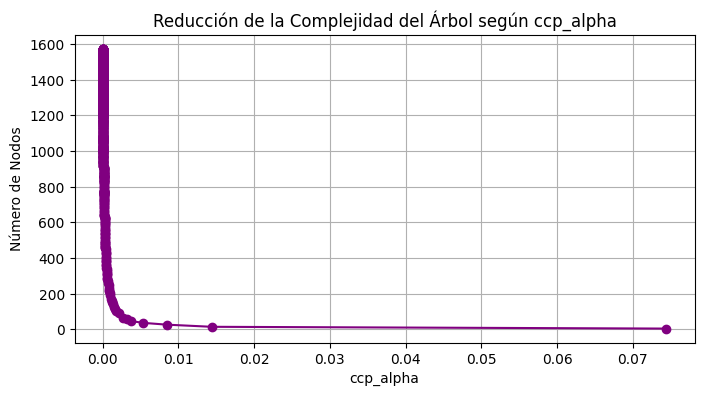

In [7]:
# Contar el número de nodos para cada alpha
clfs = []
for alpha in ccp_alphas:
    model = DecisionTreeRegressor(random_state=42, max_depth=10, ccp_alpha=alpha)
    model.fit(X_train, y_train)
    clfs.append(model)

node_counts = [clf.tree_.node_count for clf in clfs]

plt.figure(figsize=(8, 4))
plt.plot(alphas, node_counts, marker='o', color='purple')
plt.xlabel("ccp_alpha")
plt.ylabel("Número de Nodos")
plt.title("Reducción de la Complejidad del Árbol según ccp_alpha")
plt.grid(True)
plt.show()

Aplicar Cost-Complexity Pruning permite controlar el sobreajuste eliminando ramas redundantes.   

El nivel de poda ideal se alcanza con un ccp_alpha muy pequeño (cercano a $0.0005$), donde el árbol reduce drásticamente su número de nodos mientras mantiene el Test RMSE en su mínimo ($\approx 0.63$).   

Aumentar ccp_alpha por encima de $0.005$ simplifica en exceso la estructura del modelo, lo que incrementa el RMSE en ambos conjuntos y conduce a un subajuste severo.

**6. Interpretacion de resultados**

¿El modelo base presenta sobreajuste? Explique
* Sí, presenta un sobreajuste severo (extreme overfitting).Al entrenar el modelo sin restricciones de profundidad (max_depth=None), el árbol alcanzó una profundidad de 34 niveles y generó 15,854 hojas, memorizando de forma perfecta el conjunto de entrenamiento ($R^2 = 1.0000$, $\text{RMSE} = 0.0000$). Sin embargo, al evaluar en el conjunto de prueba, la precisión cayó a $R^2 = 0.6221$ y el error aumentó a $\text{RMSE} = 0.7037$. La brecha masiva entre ambos conjuntos demuestra que el árbol no logró generalizar patrones sino memorizar ruido específico.


¿Cómo afecta la profundidad del árbol al error?
* La profundidad regula directamente el compromiso Sesgo-Varianza (Bias-Variance Tradeoff): La Profundidad baja ($1$ a $5$) genera alto sesgo (subajuste / underfitting). El árbol es demasiado simple para capturar los patrones de los datos, resultando en un RMSE elevado tanto en entrenamiento como en prueba. La profundidad óptima ($8$ a $9$) alcanza el mínimo error en el conjunto de prueba ($\text{RMSE} \approx 0.64$), logrando el mejor equilibrio de generalización. Profundidad alta ($> 10$) provoca alta varianza (sobreajuste / overfitting). El RMSE de entrenamiento continúa reduciéndose hacia cero mientras que el RMSE de prueba comienza a rebotar e incrementarse progresivamente.

¿Qué efecto tiene la poda en el modelo?

* La poda por complejidad de costo (Cost-Complexity Pruning con ccp_alpha) elimina ramas y nodos redundantes que aportan poco valor predictivo. Reduce drásticamente el número de nodos del árbol (de casi 1,600 nodos a menos de 100) con incrementos sutiles de $\alpha$. Al podar el ruido, disminuye el error de prueba (Test RMSE $\approx 0.63$), cerrando la brecha entre el entrenamiento y la prueba.Si el valor de ccp_alpha se incrementa en exceso ($> 0.005$), el modelo se simplifica demasiado y cae en subajuste, disparando el RMSE.


¿Cuál configuración produce el mejor desempeño?

* La mejor configuración para el dataset de California Housing se obtiene mediante cualquiera de estas dos vías de regularización.
  * Poda por Profundidad: max_depth = 8 (alcanza el punto óptimo del compromiso Sesgo-Varianza con $\text{RMSE} \approx 0.64$ y un $R^2 \approx 0.68$).
  * Poda por Complejidad: ccp_alpha ≈ 0.0005 (logra simplificar el árbol de forma óptima manteniendo un $\text{RMSE} \approx 0.63$).   


¿Qué variables son más relevantes según el modelo?

* Generalmente, las variables más importantes que determina el árbol para California Housing son:
  * MedInc (Ingreso Medio): Es con diferencia el predictor más dominante (suele aportar entre el $50\%$ y $60\%$ de la importancia total del árbol). Existe una correlación directa entre la riqueza promedio de la zona y el valor de las viviendas.
  * Ubicación Geográfica (Latitude y Longitude): Capturan el efecto del costo de vida regional y la cercanía a la costa o zonas metropolitanas principales (como San Francisco o Los Ángeles).
  * AveOccup / HouseAge: Aportan valor secundario explicando la densidad poblacional y la antigüedad promedio de los inmuebles.



In [8]:
pd.Series(arbol_base.feature_importances_, index=X.columns).sort_values(ascending=False)

,0
MedInc,0.528509
AveOccup,0.130838
Latitude,0.093717
Longitude,0.082902
AveRooms,0.052975
HouseAge,0.051884
Population,0.030516
AveBedrms,0.028660
